<a href="https://colab.research.google.com/github/siojzz/Practical-Statistics-for-Data-Scientists/blob/main/PracticalStatisticsChapter5_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 5 - Classification

This notebook contains my code reproduction and notes for Chapter 5 of *Practical Statistics for Data Scientists*.

This chapter focuses on classification methods used to predict categorical outcomes. The main topics include Naive Bayes, Linear Discriminant Analysis, Logistic Regression, classification metrics, ROC curves, AUC, and imbalanced data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    roc_curve,
    roc_auc_score
)

import statsmodels.api as sm

In [2]:
base = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data"

!wget -O loan_data.csv.gz "{base}/loan_data.csv.gz"
!wget -O loan3000.csv "{base}/loan3000.csv"

--2026-10-24 11:03:23--  https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/loan_data.csv.gz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1268457 (1.2M) [application/octet-stream]
Saving to: ‘loan_data.csv.gz’

loan_data.csv.gz    100%[===================>]   1.21M  --.-KB/s    in 0.02s   

2026-10-24 11:03:24 (51.1 MB/s) - ‘loan_data.csv.gz’ saved [1268457/1268457]

--2026-10-24 11:03:24--  https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/loan3000.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connec

In [3]:
loan_data = pd.read_csv("loan_data.csv.gz")
loan3000 = pd.read_csv("loan3000.csv", index_col=0)

loan_data["outcome"] = loan_data["outcome"].astype("category")
loan3000["outcome"] = loan3000["outcome"].astype("category")

loan_data.head()

,Unnamed: 0,status,loan_amnt,term,annual_inc,dti,payment_inc_ratio,revol_bal,revol_util,purpose,...,delinq_2yrs_zero,pub_rec_zero,open_acc,grade,outcome,emp_length,purpose_,home_,emp_len_,borrower_score
0,1,Charged Off,2500,60 months,30000,1.00,2.39320,1687,9.4,car,...,1,1,3,4.8,default,1,major_purchase,RENT,> 1 Year,0.65
1,2,Charged Off,5600,60 months,40000,5.55,4.57170,5210,32.6,small_business,...,1,1,11,1.4,default,5,small_business,OWN,> 1 Year,0.80
2,3,Charged Off,5375,60 months,15000,18.08,9.71600,9279,36.5,other,...,1,1,2,6.0,default,1,other,RENT,> 1 Year,0.60
3,4,Charged Off,9000,36 months,30000,10.08,12.21520,10452,91.7,debt_consolidation,...,1,1,4,4.2,default,1,debt_consolidation,RENT,> 1 Year,0.50
4,5,Charged Off,10000,36 months,100000,7.06,3.90888,11997,55.5,other,...,1,1,14,5.4,default,4,other,RENT,> 1 Year,0.55


## 1. Naive Bayes

Naive Bayes is a classification method based on probability.

The method assumes that predictor variables are conditionally independent from each other given the outcome class.

Even though this assumption is often unrealistic, Naive Bayes can still work well for many classification problems.

In [4]:
predictors = ["purpose_", "home_", "emp_len_"]
outcome = "outcome"

X = pd.get_dummies(
    loan_data[predictors],
    prefix="",
    prefix_sep=""
)

y = loan_data[outcome]

naive_model = MultinomialNB(
    alpha=0.01,
    fit_prior=True
)

naive_model.fit(X, y)

MultinomialNB(alpha=0.01)

In [5]:
new_loan = X.loc[146:146, :]

print(
    "Predicted class:",
    naive_model.predict(new_loan)[0]
)

probabilities = pd.DataFrame(
    naive_model.predict_proba(new_loan),
    columns=naive_model.classes_
)

probabilities

Predicted class: default


,default,paid off
0,0.653696,0.346304


**Interpretation:**

Naive Bayes predicts the class of the new loan using the probability of each outcome.

The model also provides probabilities for the possible classes, such as default and paid off.

## 2. Linear Discriminant Analysis

Linear Discriminant Analysis (LDA) is a classification method that tries to separate classes using a linear combination of predictor variables.

The goal is to maximize the separation between classes while minimizing variation within each class.

In [6]:
predictors = [
    "borrower_score",
    "payment_inc_ratio"
]

outcome = "outcome"

X = loan3000[predictors]
y = loan3000[outcome]

loan_lda = LinearDiscriminantAnalysis()

loan_lda.fit(X, y)

LinearDiscriminantAnalysis()

In [7]:
pd.DataFrame(
    loan_lda.scalings_,
    index=X.columns,
    columns=["LD1"]
)

,LD1
borrower_score,7.175839
payment_inc_ratio,-0.099676


In [8]:
pred = pd.DataFrame(
    loan_lda.predict_proba(X),
    columns=loan_lda.classes_
)

pred.head()

,default,paid off
0,0.553544,0.446456
1,0.558953,0.441047
2,0.272696,0.727304
3,0.506254,0.493746
4,0.609952,0.390048


**Interpretation:**

LDA combines the predictor variables to create a linear boundary between the loan outcome classes.

The predicted probabilities show how likely each loan is to belong to the default or paid-off class.

## 3. Logistic Regression

Logistic regression is used to predict a categorical outcome, especially a binary outcome.

Unlike linear regression, logistic regression predicts the probability that an observation belongs to a particular class.

The probability can then be converted into a class using a cutoff value such as 0.5.

In [9]:
predictors = [
    "payment_inc_ratio",
    "purpose_",
    "home_",
    "emp_len_",
    "borrower_score"
]

outcome = "outcome"

X = pd.get_dummies(
    loan_data[predictors],
    prefix="",
    prefix_sep="",
    drop_first=True
)

y = loan_data[outcome]

logit_reg = LogisticRegression(
    penalty="l2",
    C=1e42,
    solver="liblinear"
)

logit_reg.fit(X, y)

LogisticRegression(C=1e+42, solver='liblinear')

In [10]:
logit_reg.classes_

array(['default', 'paid off'], dtype=object)

In [11]:
predicted_class = logit_reg.predict(X)

predicted_probability = logit_reg.predict_proba(X)

print(predicted_class[:5])
print(predicted_probability[:5])

['paid off' 'paid off' 'default' 'default' 'paid off']
[[0.24250183 0.75749817]
 [0.31440727 0.68559273]
 [0.51662729 0.48337271]
 [0.58799976 0.41200024]
 [0.45861809 0.54138191]]


**Interpretation:**

Logistic regression estimates the probability of each loan outcome.

The class with the higher predicted probability is selected as the predicted outcome.

## 4. Evaluating Classification Models

Classification models should not only be evaluated using accuracy.

A confusion matrix shows correct and incorrect predictions for each class.

It contains true positives, true negatives, false positives, and false negatives.

In [12]:
pred_y = logit_reg.predict(X)

conf_mat = confusion_matrix(
    y,
    pred_y,
    labels=logit_reg.classes_
)

pd.DataFrame(
    conf_mat,
    index=[
        f"Actual {x}"
        for x in logit_reg.classes_
    ],
    columns=[
        f"Predicted {x}"
        for x in logit_reg.classes_
    ]
)

,Predicted default,Predicted paid off
Actual default,14336,8335
Actual paid off,8148,14523


**Interpretation:**

The diagonal values represent correct predictions.

The values outside the diagonal represent incorrect predictions made by the classifier.

### 4.1 Precision and Recall

Precision measures how many predicted positive cases are actually positive.

Recall measures how many actual positive cases are correctly identified by the model.

These metrics are especially important when one class is more important or less common than the other.

In [13]:
true_default = (
    y == "default"
).astype(int)

pred_default = (
    pred_y == "default"
).astype(int)

precision = precision_score(
    true_default,
    pred_default
)

recall = recall_score(
    true_default,
    pred_default
)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.6376089663760897
Recall: 0.6323496978518812


## 5. ROC Curve

The ROC curve shows the trade-off between the true positive rate and false positive rate at different classification thresholds.

A model with better classification performance produces a curve closer to the upper-left corner.

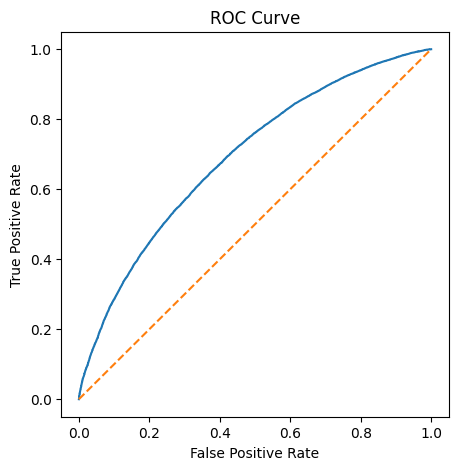

In [14]:
default_index = list(
    logit_reg.classes_
).index("default")

default_prob = logit_reg.predict_proba(X)[
    :,
    default_index
]

fpr, tpr, thresholds = roc_curve(
    true_default,
    default_prob
)

plt.figure(figsize=(5, 5))

plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

## 6. AUC

AUC stands for Area Under the ROC Curve.

It summarizes classifier performance using one value.

An AUC of 0.5 represents performance similar to random guessing, while an AUC closer to 1 indicates better classification performance.

In [15]:
auc = roc_auc_score(
    true_default,
    default_prob
)

print("AUC:", auc)

AUC: 0.6917108731135808


## 7. Lift

Lift measures how much better a model is at identifying the class of interest compared with random selection.

It is useful when the important class is relatively rare and only the highest-ranked predictions will be selected.

## 8. Strategies for Imbalanced Data

Imbalanced data occurs when one class has many more observations than another class.

This can make accuracy misleading because a model may predict the majority class most of the time and still obtain high accuracy.

Common strategies include:

- Undersampling
- Oversampling
- Class weighting
- Data generation

In [16]:
default_weight = (
    1 /
    np.mean(
        loan_data["outcome"] == "default"
    )
)

weights = [
    default_weight
    if value == "default"
    else 1
    for value in loan_data["outcome"]
]

weighted_model = LogisticRegression(
    penalty="l2",
    C=1e42,
    solver="liblinear"
)

weighted_model.fit(
    X,
    y,
    sample_weight=weights
)

LogisticRegression(C=1e+42, solver='liblinear')


**Interpretation:**

Class weighting gives more importance to observations from the less common class.

This can help the model pay more attention to default cases instead of being dominated by the majority class.

## 9. Chapter Summary

In this chapter, I learned how classification methods are used to predict categorical outcomes.

The main topics covered were:

- Naive Bayes
- Linear Discriminant Analysis
- Logistic Regression
- Predicted class probabilities
- Confusion Matrix
- Precision and Recall
- ROC Curve
- AUC
- Lift
- Imbalanced data
- Undersampling and oversampling
- Class weighting

Classification is useful when the target variable contains categories rather than continuous numerical values.

Model evaluation should consider more than accuracy, especially when the classes are imbalanced.